In [1]:
# try:
#     import uv
# except:
#     !pip install uv

# if not torch.cuda.is_available():
#     !uv pip uninstall --system tensorflow && uv pip install --system tensorflow-cpu

In [ ]:
!git clone git://github.com/manujosephv/pytorch_tabular
!pip install .

In [ ]:
try:
    from pytorch_tabular import TabularModel
except:
    !pip install "pytorch_tabular[extra]" && pip install "pytorch_tabular"
    from pytorch_tabular import TabularModel

try:
    import captum
except:
    !pip install -q captum
    import captum

In [1]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'GPU: Tesla T4'

In [ ]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [8]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import shutil
import itertools
from tqdm.auto import tqdm
from time import time, sleep

from sklearn.calibration import CalibrationDisplay
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import roc_auc_score, log_loss, RocCurveDisplay
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, RobustScaler, TargetEncoder as skTE

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)

In [10]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 10,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [11]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --

PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH = "/kaggle/input/competitions/playground-series-s6e9/"
    submission = pd.read_csv(PATH+'sample_submission.csv')
    train = pd.read_csv(PATH+'train.csv')
    test = pd.read_csv(PATH+'test.csv')

    ORIG_PATH = "/kaggle/input/datasets/itzzomkar/ev-adoption-behavior-and-range-anxiety/"
    orig = pd.read_csv(ORIG_PATH+"EV_Adoption_and_Range_Anxiety_Dataset.csv")
elif PLATFORM == 'colab':
    from google.colab import drive
    drive.mount('/content/drive')

    PATH = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e8 | Phone Addiction/_phone_addiction_data/"
    submission = pd.read_csv(PATH+"sample_submission.csv")
    train = pd.read_csv(PATH+"train.csv")
    test = pd.read_csv(PATH+"test.csv")
    orig = pd.read_csv(PATH+"Smartphone_Usage_And_Addiction_Analysis_7500_Rows.csv")

## =================================================================================

ID     = "id"
TARGET = 'Will_Buy_EV'

obj = train.select_dtypes(include=["object", "category"]).columns.tolist()

cat_cols = [c for c in obj if c not in [TARGET, ID]]
num_cols = [c for c in train.columns if c not in cat_cols+[TARGET, ID]]
base_cols = num_cols + cat_cols

train[TARGET] = train[TARGET].map({'No': 0, 'Yes': 1})
orig[TARGET] = orig[TARGET].map({'No': 0, 'Yes': 1})

for (name, df) in {"Train": train, "Test": test , "Orig": orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nTotal Nums: {len(num_cols)}")
print(f"Total Cats: {len(cat_cols)}")
print(f"Total base: {len(base_cols)}")

Train shape: (668665, 15)
Test shape: (286571, 14)
Orig shape: (10000, 15)

Total Nums: 7
Total Cats: 6
Total base: 13


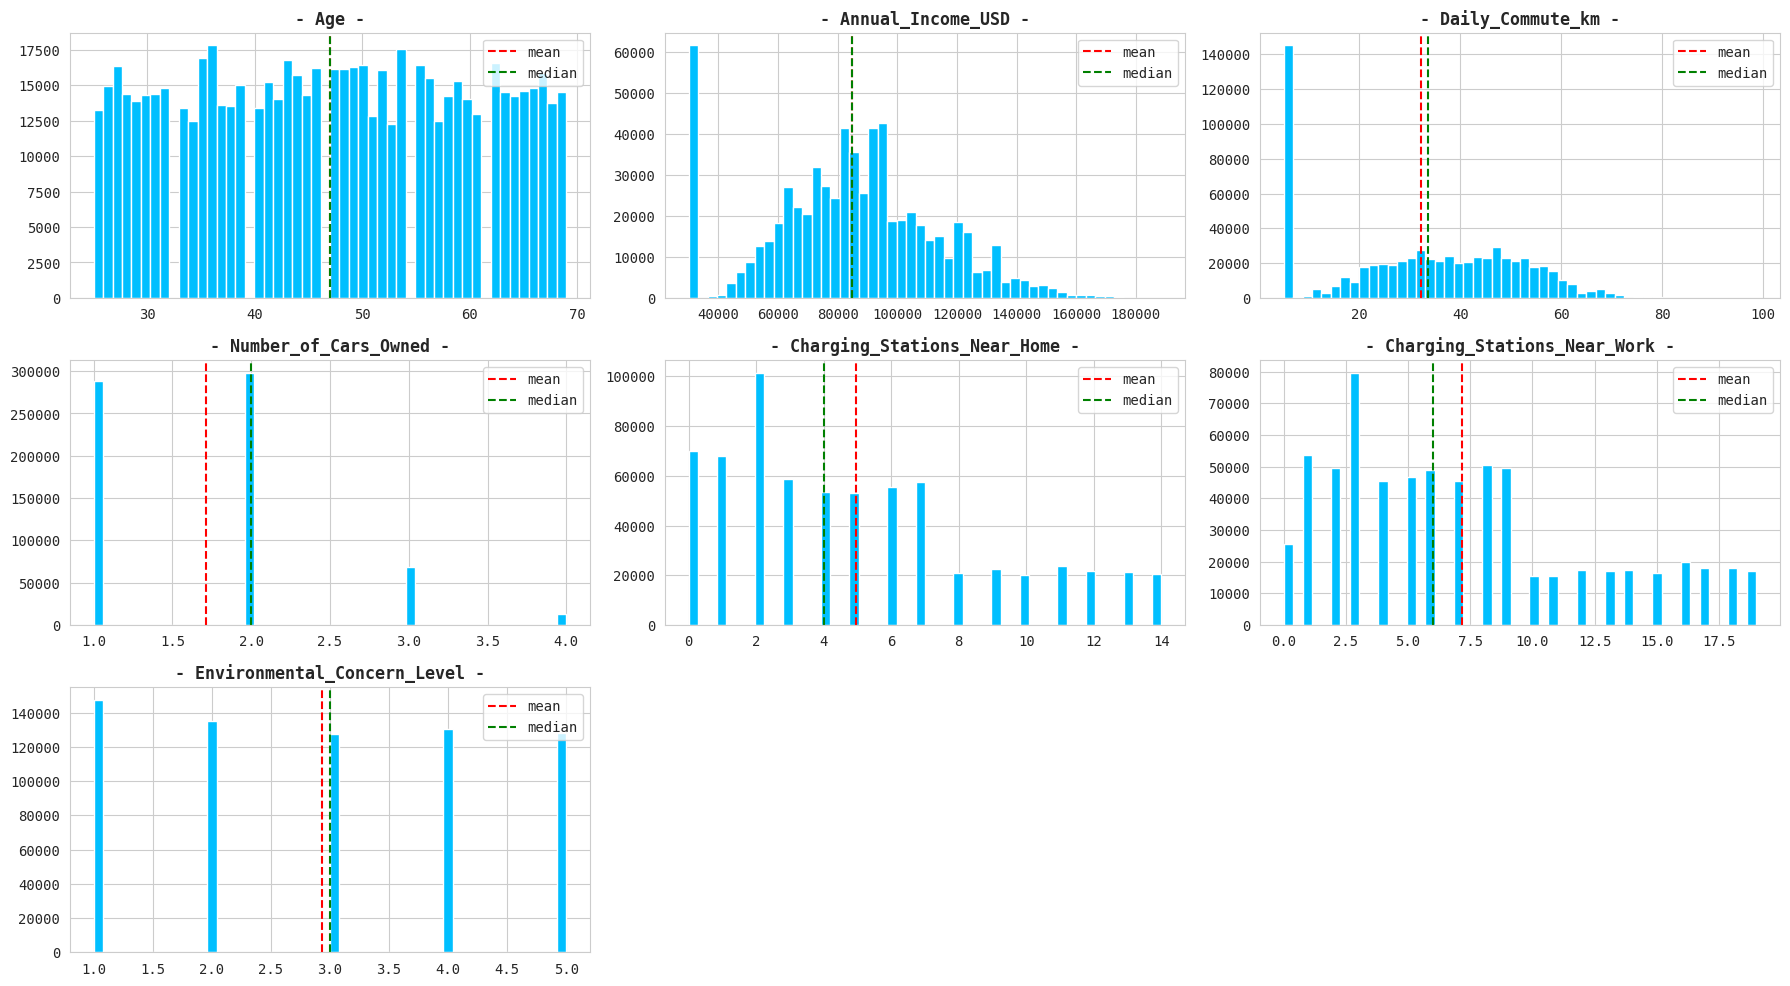

In [16]:
plt.figure(figsize=(18, 13))

for i, col in enumerate(num_cols):
    plt.subplot(4, 3, i+1)
    ax = plt.hist(train[col], bins=50)
    plt.axvline(x=train[col].mean(), color='r', linestyle='--', label='mean')
    plt.axvline(x=train[col].median(), color='g', linestyle='--', label='median')
    plt.title(f'- {col} -', fontweight='semibold')
    plt.legend()
plt.tight_layout()
plt.show()

In [17]:
def get_class_weights(y):
    """
    y: Current y_labels -> array_like or series
    """
    weights_ = compute_class_weight('balanced', classes=np.unique(y), y=y)
    return weights_

def get_sample_weights(y, y_true):
    """
    y: Current y labels -> numpy array or series
    y_true: True labels -> numpy array or series
    """
    classes_ = np.unique(y_true)
    weights_ = compute_class_weight('balanced', classes=classes_, y=y_true)
    class_weights = dict(zip(classes_, weights_))
    return np.array([class_weights[label] for label in y])

print("- Helper Functions Ready -")

- Helper Functions Ready -


## FEATURE ENGINEERING

In [18]:
# def apply_feature_engineering(df_, num_features_, cat_features_):
#     df = df_.copy()

#     # num_to_cat = []
#     # for col in num_features_:
#     #     cat_name = f"{col}_cat"
#     #     df[cat_name] = df[col].fillna('NaN').astype(str)
#     #     num_to_cat.append(cat_name)

#     # for c in num_features_:
#     #     for i in [0,1]:
#     #         df[f"{c}_round{i}"] = df[c].round(i)

#     social = df['social_media_hours']
#     gaming = df['gaming_hours']
#     work = df['work_study_hours']
#     daily = df['daily_screen_time_hours']
#     sleep = df['sleep_hours']
#     weekend = df['weekend_screen_time']
#     opens = df['app_opens_per_day']
#     notifications = df['notifications_per_day']

#     df['total_breakdown_hours'] = social.fillna(0) + gaming.fillna(0) + work.fillna(0)
#     df['social_ratio'] = social / (daily + 1e-5)
#     df['gaming_ratio'] = gaming / (daily + 1e-5)
#     df['work_ratio'] = work / (daily + 1e-5)
#     df['unaccounted_screen_time'] = daily - df['total_breakdown_hours']
#     df['screen_to_sleep_ratio'] = daily / (sleep + 1e-5)
#     df['weekend_vs_daily_ratio'] = weekend / (daily + 1e-5)
#     df['app_opens_per_hour'] = opens / (daily + 1e-5)
#     df['notifications_per_hour'] = notifications / (daily + 1e-5)

#     COMP = ['social_media_hours', 'gaming_hours', 'work_study_hours']
#     n_missing_components = df[COMP].isna().sum(axis=1)
#     missing_daily = daily.isna()
#     known_component_sum = df[COMP].sum(axis=1, min_count=1)
#     slack = daily - known_component_sum
#     daily_missing_with_components = missing_daily & (n_missing_components == 0)
#     one_component_missing = (~missing_daily) & (n_missing_components == 1)
#     all_screen_known = (~missing_daily) & (n_missing_components == 0)

#     df['ci_daily_lb'] = np.where(daily_missing_with_components, known_component_sum, np.nan)
#     df['ci_missing_comp_ub'] = np.where(one_component_missing, slack, np.nan)
#     df['ci_missing_comp_mid'] = np.where(one_component_missing, np.clip(slack / 2, 0, None), np.nan)
#     df['ci_interval_width'] = np.where(one_component_missing, slack, np.nan)
#     df['ci_slack_exact'] = np.where(all_screen_known, slack, np.nan)
#     df['ci_case'] = np.select([daily_missing_with_components, one_component_missing], [1.0, 2.0], default=0.0).astype('float32')
#     df['ci_n_missing'] = (missing_daily.astype('int8') + n_missing_components).astype('float32')
    
#     df['missing_count'] = df[num_features_+cat_features_].isna().sum(axis=1).astype('int8')
        
#     drop = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
#     if drop:
#         df.drop(drop, axis=1, inplace=True)

#     return df

# train = apply_feature_engineering(train, num_cols, CATS)
# test  = apply_feature_engineering(test, num_cols, CATS)
# orig  = apply_feature_engineering(orig, num_cols, CATS)

# NEW_CATS = ["ci_case", "ci_n_missing", "missing_count"]
# train[NEW_CATS] = train[NEW_CATS].fillna(-1)
# test[NEW_CATS]  = test[NEW_CATS].fillna(-1)
# # orig[NEW_CATS]  = orig[NEW_CATS].fillna(-1)

# CATS.extend(NEW_CATS)

# train

In [19]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class customTE(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}
        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)
        return X

In [20]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    for col in tqdm(valid_features, desc="TE_merging"):
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"OTE_{col}_{agg_key}"

            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = (orig.groupby(col)[target].mean().reset_index(name=new_col))
                    elif agg_key == 'median':
                        map_df = (orig.groupby(col)[target].median().reset_index(name=new_col))
                    elif agg_key == 'count':
                        map_df = (orig.groupby(col).size().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'nunique':
                        map_df = (orig.groupby(col)[target].nunique().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'std':
                        map_df = (orig.groupby(col)[target].std().reset_index(name=new_col))
                    elif agg_key == 'skew':
                        map_df = (orig.groupby(col)[target].skew().reset_index(name=new_col))
                    elif agg_key == 'max':
                        map_df = (orig.groupby(col)[target].max().reset_index(name=new_col))
                    elif agg_key == 'min':
                        map_df = (orig.groupby(col)[target].min().reset_index(name=new_col))
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df, on=col, how='left')

            orig_cols.append(new_col)

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if '_mean' in c or '_max' in c or '_min' in c:
                df[c] = df[c].fillna(global_mean)
            elif '_median' in c:
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


In [21]:
# ## -- "mean", "median", "count", "std", "skew", "nunique", "max", "min"
# orig_aggs = ["mean"]

# train, orig_cols = orig_TE_data_propagate(
#     orig,
#     train,
#     features=BASE,
#     target=TARGET,
#     aggs=orig_aggs,
#     fill_nan=True,
# )

# test, _ = orig_TE_data_propagate(
#     orig,
#     test,
#     features=BASE,
#     target=TARGET,
#     aggs=orig_aggs,
#     fill_nan=True,
# )

# train[orig_cols][:10].T

In [22]:
# imputer_ = IterativeImputer(add_indicator=True).set_output(transform='pandas')
# scaler__ = StandardScaler().set_output(transform='pandas')

# df = imputer_.fit_transform(scaler__.fit_transform(train[:10][num_cols].copy()))

# df

In [23]:
# ## -- Get NaN indicators --
# def appy_nan_indicator(df, indicate_cols: list=None):
#     cols_with_nan = df[indicate_cols].columns[df[indicate_cols].isna().any()]
#     indicators = df[cols_with_nan].isna().astype(int).add_prefix("isna_")

#     return df.join(indicators), indicators.columns.tolist()

# train, INDI_COLS = appy_nan_indicator(train, num_cols)
# test, _  = appy_nan_indicator(test, num_cols)
# orig, _  = appy_nan_indicator(orig, num_cols)

# print(f"Total missing indicators: {len(INDI_COLS)}")
# print(INDI_COLS)

# train

In [24]:
# FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
# print("Features before:", len(FEATURES))

# combined = pd.concat([train, test, orig])

# ## ------------------------------------------------------------
# ## -- Duplicate Nums as Cats --
# TE_CATS = []
# for c in num_cols:
#     n = f"cat_{c}"
#     combined[n] = combined[c].factorize()[0]
#     # combined[n] = combined[n].astype('category')
#     TE_CATS.append(n)
# FEATURES.extend(TE_CATS)
# print("Nums to Cats complete!")
# ## ------------------------------------------------------------
# ## -- Factorize all CATS data --
# # for c in CATS:
# #     combined[c] = combined[c].factorize()[0]
#     # combined[c] = combined[c].astype('category')
# # print("Label encoding complete!")
# ## ------------------------------------------------------------

# print("Features after:", len(FEATURES))

# train = combined.iloc[:len(train)][FEATURES+[TARGET]]
# test  = combined.iloc[len(train):len(train)+len(test)][FEATURES]
# orig  = combined.iloc[len(train)+len(test):]

# del combined

# train

In [25]:
FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print('Total Features:', len(FEATURES))

train

Total Features: 13


,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,0,66,92887.0,23.4,2,3,7,1.0,Male,Suburban,Sedan,Yes,No,Low,0
1,1,38,30000.0,5.0,1,2,2,4.0,Male,Rural,SUV,Yes,No,Low,0
2,2,26,94389.0,36.8,1,8,15,5.0,Female,Urban,Sedan,No,Yes,Low,1
3,3,66,73580.0,23.7,2,6,9,3.0,Male,Suburban,Hatchback,Yes,No,Low,0
4,4,54,57898.0,50.8,1,2,3,3.0,Male,Suburban,Hatchback,Yes,No,Low,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
668660,668660,30,71090.0,27.4,2,5,6,5.0,Male,Urban,Sedan,No,Yes,Medium,0
668661,668661,32,129990.0,5.0,2,5,4,1.0,Female,Suburban,SUV,Yes,Yes,Low,0
668662,668662,64,121791.0,24.2,1,5,6,1.0,Female,Suburban,Hatchback,Yes,Yes,Low,0
668663,668663,51,115923.0,43.7,2,0,0,1.0,Female,Rural,SUV,Yes,Yes,Low,0


# ML TRAINING

In [ ]:
from pytorch_tabular import model_sweep, available_models, MODEL_SWEEP_PRESETS
from pytorch_tabular.config import DataConfig, OptimizerConfig, TrainerConfig
from pytorch_tabular.models.common.heads import LinearHeadConfig
from pytorch_tabular.models import (
            AutoIntConfig,
            CategoryEmbeddingModelConfig,
            DANetConfig,
            FTTransformerConfig,
            GANDALFConfig,
            GatedAdditiveTreeEnsembleConfig,
            MDNConfig,
            NodeConfig,
            StackingModelConfig,
            TabNetModelConfig,
            TabTransformerConfig,
)

display(available_models())

print()

for variant in list(MODEL_SWEEP_PRESETS.keys()):
    print(f"{CFG['YELLOW']}{variant} edition:")
    display(MODEL_SWEEP_PRESETS[variant])

In [ ]:
all_predictions = {}

LR = 0.01
TASK = "classification"

ALL_CATS = CATS #+ INDI_COLS

CFG['FOLDS'] = 5
skf = StratifiedKFold(n_splits=CFG['FOLDS'], shuffle=True, random_state=CFG['SEED'])

USE_FULL_TRAIN = False
x_sample, x_sample2 = train_test_split(train, train_size=0.2, stratify=train[TARGET], random_state=42)

train_data = train.copy() if USE_FULL_TRAIN else x_sample.copy()
train_data

## SWEEP TRAINER

In [ ]:
def Sweeper_CV(train_df, test_df, features, target, kfold, model_list='lite',
    process_type=None, cat_cols=None, num_cols=None, use_original=False):

    print(f"\n===== Sweeper models CV | {get_system_info()} =====")
    t0 = time()

    X = train_df[features]
    y = train_df[target]
    X_test = test_df[features]

    num_cls = y.nunique()

    oof_preds    = np.zeros(len(X))
    test_preds   = np.zeros(len(test_df))
    eval_results = {}
    
    # Handle optional original table aggregations securely if flags enable them
    if use_original and "original_TE" in globals():
        X_tr, orig_cols = orig_TE_data_propagate(
            orig, train_df, target=target, features=BASE, aggs=["mean"], fill_nan=True
        )
        x_test, _ = orig_TE_data_propagate(
            orig, test_df, target=target, features=BASE, aggs=["mean"], fill_nan=True
        )
        features.extend(orig_cols)
        X = X_tr[features].copy()
        y = X_tr[target].astype("int8")
        X_ts = x_test[features].copy()
    else:
        X = train_data[features].copy()
        y = train_data[target].astype("int8")
        X_ts = test[features].copy()

    for idx, (train_idx, val_idx) in enumerate(kfold.split(X, y), 1):
        print(f"\n+++++ FOLD {idx}/{kfold.n_splits}", end=" | ")

        X_train, X_valid = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_valid = y.iloc[train_idx], y.iloc[val_idx]
        # X_test = X_ts.copy()

        # ## -- OPTION A: Concatenate original data --
        # X_train = pd.concat([X_train, orig[FEATURES]], ignore_index=True)
        # y_train = pd.concat([y_train, orig[TARGET]], ignore_index=True)
        # y_train = np.concatenate([y_train, orig[TARGET].values], axis=0)

        # ## -- Handle missing numeric data --
        scaler = StandardScaler()
        X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
        X_valid[num_cols] = scaler.transform(X_valid[num_cols])
        X_test[num_cols]  = scaler.transform(X_test[num_cols])

        # estimator = HistGradientBoostingRegressor(random_state=0)
        imputer = IterativeImputer(max_iter=20, tol=1e-3, random_state=0)
        X_train[num_cols] = imputer.fit_transform(X_train[num_cols])
        X_valid[num_cols] = imputer.transform(X_valid[num_cols])
        X_test[num_cols]  = imputer.transform(X_test[num_cols])

        # te_enc  = customTE(TE_CATS, cv=5, smooth='auto', aggs=['mean'], drop_original=True)
        # X_train = te_enc.fit_transform(X_train, y_train)
        # X_valid = te_enc.transform(X_valid)
        # X_test  = te_enc.transform(X_test)

        # # Explicitly cast numerical columns to float32 and target to int64
        # X_train[num_cols] = X_train[num_cols].astype('float32')
        # X_valid[num_cols] = X_valid[num_cols].astype('float32')
        # X_test[num_cols] = X_test[num_cols].astype('float32')
        # y_train = y_train.astype('int64')
        # y_valid = y_valid.astype('int64')

        if idx == 1:
            print(f"shape: {X_train.shape}")
            display(pd.concat([X_train, y_train], axis=1).head(3))

        ## -- Define cat features for cat embeddings --
        data_config = DataConfig(
            target           = [target],
            continuous_cols  = num_cols,
            categorical_cols = cat_cols,
            normalize_continuous_features = False, # True if NOT Standardized
            # pin_memory       = True, # GPU
            # num_workers      = os.cpu_count(),
        )
        ## ---------------------------------------------------------------------------------
        optimizer_config = OptimizerConfig() # optimizer_params={'weight_decay':1e-2}
        # optimizer_config = OptimizerConfig(
        #     optimizer="torch_optimizer.QHAdam",
        #     optimizer_params={"nus": (0.7, 1.0), "betas": (0.95, 0.998)},
        #     lr_scheduler="CosineAnnealingWarmRestarts",
        #     lr_scheduler_params={"T_0": 10, "T_mult": 1, "eta_min": 1e-5},
        # )

        CHECKPOINT = "/checkpoints"
        os.makedirs(CHECKPOINT, exist_ok=True)

        trainer_config = TrainerConfig(
            # auto_lr_find=True,  # automatically derives a learning_rate
            # accelerator       = 'gpu', # 'auto'
            batch_size = 128,
            max_epochs = 50, # 100
            early_stopping_patience = 5, # 10
            # early_stopping    = 'valid_accuracy', # None, def='valid_loss',
            # early_stopping_mode = 'max', # 'min'
            # checkpoints       = 'valid_accuracy', # "valid_loss"
            # checkpoints_mode  = 'max', # 'min'
            checkpoints_path = CHECKPOINT,
            # gradient_clip_val = 1.0, # added
            seed = CFG['SEED'],
            # devices = -1,
        )

        head_config = LinearHeadConfig(
            layers="",
            # dropout=0.1,
            initialization=("kaiming"),
        ).__dict__  # Convert to dict to pass to the model config (OmegaConf doesn't accept objects)

        sweep_df, best_model = model_sweep(
            task  = TASK, #"classification", "regression"
            seed  = CFG["SEED"],
            train = pd.concat([X_train, y_train], axis=1),
            test  = pd.concat([X_valid, y_valid], axis=1),
            data_config      = data_config,
            optimizer_config = optimizer_config,
            trainer_config   = trainer_config,
            model_list       = model_list,
            # common_model_args = {"head": "LinearHead", "head_config": head_config},
            ## -----------------------------------------------------
            metrics = ["auroc"],
            metrics_prob_input = [True],
            metrics_params = [{"num_classes": num_cls}],
            rank_metric = ("auroc", "higher_is_better"),
            ## -----------------------------------------------------
            # return_best_model = True,
            # progress_bar = True,
            # verbose = True,
            # suppress_lightning_logger = True,
        )
        # ============================================================================
        display(sweep_df.drop(columns=["params", "time_taken_per_epoch", "epochs"])\
                        .style.background_gradient(subset=["test_auroc"], cmap="RdYlGn")\
                        .background_gradient(subset=["time_taken", "test_loss"], cmap="RdYlGn_r"))

        eval_results[f"Fold_{idx}"] = sweep_df

        ## -- Clear checkpoint logs --
        shutil.rmtree(CHECKPOINT, ignore_errors=True)

    print('-'*40)
    print(f"Total render time: {(time()-t0)/60:.2f} mins")
    print('-'*40)

    return eval_results

print("Sweeper function ready!")

In [31]:
# !rm -r /kaggle/working

In [32]:
# common_params = {
#     "task": TASK,
#     "learning_rate": LR,
#     "seed": CFG['SEED'],
#     # "batch_norm_continuous_input": False,
#     # "head":"LinearHead", "head_config": head_config
# }

# model_list = [
#     CategoryEmbeddingModelConfig(**common_params, layers="256-128-64"),
#     GANDALFConfig(**common_params),
#     TabTransformerConfig(**common_params),
#     DANetConfig(**common_params),
#     # --------------------------------------------------------------------
#     # FTTransformerConfig(**common_params, attn_feature_importance=False),
#     # --------------------------------------------------------------------
#     # NodeConfig(**common_params), #, num_trees=500 , max_features=int(np.ceil(len(FEATURES)*0.6))
#     # GatedAdditiveTreeEnsembleConfig(**common_params),
#     # AutoIntConfig(**common_params),
#     # --------------------------------------------------------------------
#     # TabNetModelConfig(**common_params, n_d=4, n_a=4), # n_d=4, n_a=4,
#     # MDNConfig(backbone_config_class='GANDALFConfig', **common_params),
# ]

# sweep_results = Sweeper_CV(
#     train_df = train_data,
#     test_df  = test,
#     features = FEATURES,
#     target   = TARGET,
#     kfold    = skf,
#     cat_cols = ALL_CATS,
#     num_cols = [c for c in FEATURES if c not in ALL_CATS+orig_cols], #num_cols,
#     model_list = model_list,
#     # use_orig = True,
# )


===== Sweeper models CV | CPU: 4 ====

##### FOLD 1/5 | shape: (82964, 33)


,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,OTE_age_mean,OTE_daily_screen_time_hours_mean,OTE_social_media_hours_mean,OTE_gaming_hours_mean,OTE_work_study_hours_mean,OTE_sleep_hours_mean,OTE_notifications_per_day_mean,OTE_app_opens_per_day_mean,OTE_weekend_screen_time_mean,OTE_gender_mean,OTE_stress_level_mean,OTE_academic_work_impact_mean,isna_age,isna_daily_screen_time_hours,isna_social_media_hours,isna_gaming_hours,isna_work_study_hours,isna_sleep_hours,isna_notifications_per_day,isna_app_opens_per_day,isna_weekend_screen_time,addicted_label
331003,1.429241,0.960495,0.093893,-0.003305,1.951762,0.169523,-0.253550,0.940013,1.715638,Male,High,No,0.705742,1.0,0.707733,0.707733,0.777778,0.65000,0.789474,0.681818,1.000000,0.722288,0.703516,0.707701,0,0,1,1,0,0,0,0,0,1
138400,1.041983,-1.111146,-0.440401,-0.017600,-1.356393,1.143034,-0.936685,-0.057640,-0.840642,Female,Low,Yes,0.727483,0.0,1.000000,0.687500,0.615385,0.75000,0.612903,0.622222,0.272727,0.702154,0.711946,0.707766,0,0,0,0,0,0,0,0,0,1
31179,-0.009725,-1.680480,-0.895048,-0.788625,-1.396155,-1.339420,0.566212,0.877660,-1.152726,Female,Medium,NaN,0.707733,0.7,0.583333,0.600000,0.818182,0.73913,0.594595,0.782609,0.500000,0.702154,0.707838,0.707733,1,0,0,0,0,0,0,0,0,0


Output()

2026-08-18 19:16:45,620 - {pytorch_tabular:345} - INFO - Training CategoryEmbeddingModel


Trainable params: 50.6 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 50.6 K                                                                                               
Total estimated model params size (MB): 0.202                                                                      
Modules in train mode: 28                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

...

┏━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name             ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ _backbone        │ GANDALFBackbone  │ 44.9 K │ train │     0 │
│ 1 │ _embedding_layer │ Embedding1dLayer │    110 │ train │     0 │
│ 2 │ _head            │ Sequential       │     74 │ train │     0 │
│ 3 │ loss             │ CrossEntropyLoss │      0 │ train │     0 │
└───┴──────────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 45.1 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 45.1 K                                                                                               
Total estimated model params size (MB): 0.181                                                                      
Modules in train mode: 39                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

2026-08-18 21:03:20,071 - {pytorch_tabular:399} - INFO - Finished Training GANDALFModel
2026-08-18 21:03:20,072 - {pytorch_tabular:400} - INFO - Results: model: GANDALFModel, # Params: 45 T, epochs: 9, test_loss_0: 0.29452621936798096, test_loss: 0.29452621936798096, test_auroc: 0.9321767091751099, time_taken: 42.483625650405884, time_taken_per_epoch: 4.720402850045098
2026-08-18 21:03:20,113 - {pytorch_tabular:345} - INFO - Training TabTransformerModel
2026-08-18 21:22:11,225 - {pytorch_tabular:399} - INFO - Finished Training TabTransformerModel
2026-08-18 21:22:11,226 - {pytorch_tabular:400} - INFO - Results: model: TabTransformerModel, # Params: 273 T, epochs: 6, test_loss_0: 0.33162200450897217, test_loss: 0.33162200450897217, test_auroc: 0.9165442585945129, time_taken: 1131.1523435115814, time_taken_per_epoch: 188.52539058526358
2026-08-18 21:22:11,258 - {pytorch_tabular:345} - INFO - Training DANetModel


┏━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name             ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ _backbone        │ DANetBackbone    │  541 K │ train │     0 │
│ 1 │ _embedding_layer │ Embedding1dLayer │    110 │ train │     0 │
│ 2 │ _head            │ LinearHead       │    130 │ train │     0 │
│ 3 │ loss             │ CrossEntropyLoss │      0 │ train │     0 │
└───┴──────────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 541 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 541 K                                                                                                
Total estimated model params size (MB): 2.165                                                                      
Modules in train mode: 168                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

In [33]:
auroc_df = []
times_df = []

def get_avg_result(score=None):
    for df in sweep_results.values():
        df_auc = df[["model", f"test_{score}"]].set_index("model").sort_index()
        df_tim = df[["model", "time_taken"]].set_index("model").sort_index()
        auroc_df.append(df_auc)
        times_df.append(df_tim)
        # display(df_auc)
        # print()

    avg_score_df = auroc_df[0].merge(
        auroc_df[1].merge(auroc_df[2], left_index=True, right_index=True),
        left_index=True, right_index=True).merge(
        auroc_df[3].merge(auroc_df[4], left_index=True, right_index=True),
        left_index=True, right_index=True
    ).mean(axis=1).round(5)
    
    avg_time_df = times_df[0].merge(
        times_df[1].merge(times_df[2], left_index=True, right_index=True),
        left_index=True, right_index=True).merge(
        times_df[3].merge(times_df[4], left_index=True, right_index=True),
        left_index=True, right_index=True
    ).mean(axis=1).round(2)

    return avg_score_df, avg_time_df

avg_score_df, avg_times_df = get_avg_result(score="auroc")
print(avg_score_df)
print()
print(avg_times_df)

model
CategoryEmbeddingModel    0.93222
DANetModel                0.93565
GANDALFModel              0.93281
TabTransformerModel       0.91795
dtype: float64

model
CategoryEmbeddingModel      57.00
DANetModel                 662.11
GANDALFModel                33.92
TabTransformerModel       1274.07
dtype: float64


In [ ]:
# base + indi_cols(nums) (8296, 21)
# model
# CategoryEmbeddingModel    0.92510
# DANetModel                0.93234
# GANDALFModel              0.92647
# TabTransformerModel       0.92136
# dtype: float64
# model
# CategoryEmbeddingModel     11.02
# DANetModel                 69.50
# GANDALFModel                4.39
# TabTransformerModel       256.85
# dtype: float64
# ---------------------------------
# base + indi_cols(all) (8296, 24)
# model
# CategoryEmbeddingModel    0.92031
# DANetModel                0.93311
# GANDALFModel              0.92872
# TabTransformerModel       0.92026
# dtype: float64
# model
# CategoryEmbeddingModel      6.19
# DANetModel                 91.11
# GANDALFModel                4.55
# TabTransformerModel       323.64
# dtype: float64
# ---------------------------------
# base (8296, 12)
# model
# CategoryEmbeddingModel    0.92214
# DANetModel                0.93352
# GANDALFModel              0.92990
# TabTransformerModel       0.92105
# dtype: float64
# model
# CategoryEmbeddingModel    12.62
# DANetModel                90.56
# GANDALFModel               4.36
# TabTransformerModel       52.59
# dtype: float64

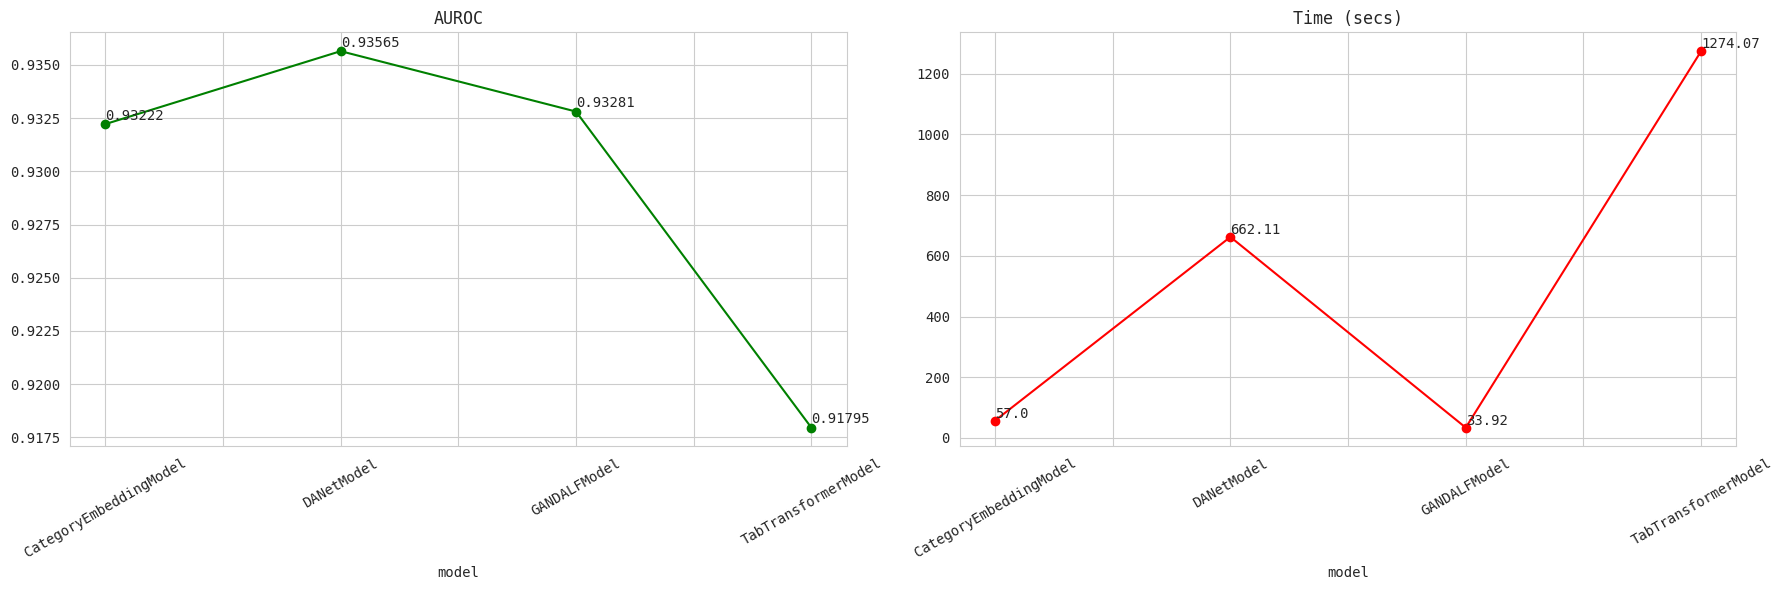

In [34]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))
avg_score_df.plot(ax=ax1, color="g", marker="o", title="AUROC")
avg_times_df.plot(ax=ax2, color="r", marker="o", title="Time (secs)")

ax1.tick_params('x', rotation=30)
ax2.tick_params('x', rotation=30)

for i, s1 in enumerate(avg_score_df.values):
    ax1.text(float(i), s1+2e-4, s1, ha="left", va="baseline")

for i, s1 in enumerate(avg_times_df.values):
    ax2.text(float(i), s1+10, s1, ha="left", va="baseline")

plt.tight_layout()
plt.show()

## MAIN TRAINER

In [35]:
train.columns

Index(['id', 'age', 'daily_screen_time_hours', 'social_media_hours',
       'gaming_hours', 'work_study_hours', 'sleep_hours',
       'notifications_per_day', 'app_opens_per_day', 'weekend_screen_time',
       'gender', 'stress_level', 'academic_work_impact', 'addicted_label',
       'OTE_age_mean', 'OTE_daily_screen_time_hours_mean',
       'OTE_social_media_hours_mean', 'OTE_gaming_hours_mean',
       'OTE_work_study_hours_mean', 'OTE_sleep_hours_mean',
       'OTE_notifications_per_day_mean', 'OTE_app_opens_per_day_mean',
       'OTE_weekend_screen_time_mean', 'OTE_gender_mean',
       'OTE_stress_level_mean', 'OTE_academic_work_impact_mean', 'isna_age',
       'isna_daily_screen_time_hours', 'isna_social_media_hours',
       'isna_gaming_hours', 'isna_work_study_hours', 'isna_sleep_hours',
       'isna_notifications_per_day', 'isna_app_opens_per_day',
       'isna_weekend_screen_time'],
      dtype='object')

In [36]:
def Trainer_CV(
    model_name, model_config, train_df, test_df, features, target, kfold,
    cat_cols=None, num_cols=None, use_orig=False):

    # print(f"\n===== Starting CV {}: {model_name} | {get_system_info()} =====")
    t0 = time()

    X = train_df[features]
    y = train_df[target]
    test_df = test_df[features]

    oof_preds  = np.zeros(len(X))
    test_preds = np.zeros(len(test_df))

    if use_orig:
        # "mean", "count", "std","median", "skew", "nunique", "max", "min"
        orig_aggs = ["mean", "count"]

        X, orig_cols = orig_TE_data_propagate(
            orig,
            X,
            features=BASE,
            target=TARGET,
            aggs=orig_aggs,
            fill_nan=True,
        )

        test_df, _ = orig_TE_data_propagate(
            orig,
            test_df,
            features=BASE,
            target=TARGET,
            aggs=orig_aggs,
            fill_nan=True,
        )

    fold_scores  = []
    feat_importances = []
    eval_results = {}

    for idx, (train_idx, val_idx) in enumerate(kfold.split(X, y), 1):
        print(f"\n##### FOLD {idx}/{kfold.n_splits}", end=" | ")

        X_train, X_valid = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_valid = y.iloc[train_idx], y.iloc[val_idx]
        X_test = test_df.copy()

        # ## -- OPTION A: Concatenate original data --
        # X_train = pd.concat([X_train, orig[FEATURES]], ignore_index=True)
        # y_train = pd.concat([y_train, orig[TARGET]], ignore_index=True)
        # y_train = np.concatenate([y_train, orig[TARGET].values], axis=0)

        # ## -- OPTION B: TE propagate original data --
        # if use_orig:
        #     X_train, orig_cols = orig_TE_data_propagate(
        #         orig,
        #         X_train,
        #         features=BASE,
        #         target=TARGET,
        #         aggs=orig_aggs,
        #         fill_nan=True,
        #     )

        #     X_valid, _ = orig_TE_data_propagate(
        #         orig,
        #         X_valid,
        #         features=BASE,
        #         target=TARGET,
        #         aggs=orig_aggs,
        #         fill_nan=True,
        #     )

        # ## -- Target Encoding --
        # print(f" • Target Encoding {len(te_cols)} features... ")
        # X_train, X_valid, X_test = t_enc_multi(X_train, X_valid, X_test, y_train, ROUNDS, drop=True)

        # if PLATFORM == "kaggle":
        #     CHECKPOINT = "/kaggle/working/checkpoints"
        # else:
        #     CHECKPOINT = "/content/checkpoints"

        CHECKPOINT = "checkpoints"
        shutil.rmtree(CHECKPOINT, ignore_errors=True)
        os.makedirs(CHECKPOINT, exist_ok=True)
        sleep(2)

        ## -- Handle missing numeric data --
        scaler = StandardScaler()
        X_train.loc[:, num_cols] = scaler.fit_transform(X_train[num_cols])
        X_valid.loc[:, num_cols] = scaler.transform(X_valid[num_cols])
        X_test.loc[:, num_cols]  = scaler.transform(X_test[num_cols])

        imputer = IterativeImputer(max_iter=20, tol=1e-3, random_state=0)
        X_train.loc[:, num_cols] = imputer.fit_transform(X_train[num_cols])
        X_valid.loc[:, num_cols] = imputer.transform(X_valid[num_cols])
        X_test.loc[:, num_cols]  = imputer.transform(X_test[num_cols])

        if idx == 1:
            print(f"shape: {X_train.shape}")
            display(X_train.head(3))

        ## -- Define cat features for cat embeddings --
        data_config = DataConfig(
            target           = [target],
            continuous_cols  = num_cols + orig_aggs if use_orig else num_cols,
            categorical_cols = cat_cols,
            normalize_continuous_features = False,
            # num_workers      = int(os.cpu_count()*0.75),
            # pin_memory       = True, # GPU
        )
        ## ---------------------------------------------------------------------------------
        optimizer_config = OptimizerConfig() # optimizer_params={'weight_decay':1e-2}
        # optimizer_config = OptimizerConfig(
        #     optimizer="torch_optimizer.QHAdam",
        #     optimizer_params={"nus": (0.7, 1.0), "betas": (0.95, 0.998)},
        #     lr_scheduler="CosineAnnealingWarmRestarts",
        #     lr_scheduler_params={"T_0": 10, "T_mult": 1, "eta_min": 1e-5},
        # )

        trainer_config = TrainerConfig(
            # auto_lr_find = True, # Runs the LRFinder to automatically derive a learning rate
            # accelerator = 'gpu', # 'auto'
            batch_size = 1024,
            max_epochs = 100, # def=10
            early_stopping_patience = 5,  # def=3
            # early_stopping = 'valid_accuracy', # def='valid_loss',
            # early_stopping_mode = 'max', # def='min'
            # checkpoints = 'valid_accuracy', # def='valid_loss',
            # checkpoints_mode = 'max', # 'min'
            checkpoints_path = CHECKPOINT, # None -> no saving
            # gradient_clip_val = 1.0, # added
            # devices = -1,
            seed = CFG['SEED'],
        )
        ## ---------------------------------------------------------------------------------
        model = TabularModel(
            data_config      = data_config,
            model_config     = model_config,
            optimizer_config = optimizer_config,
            trainer_config   = trainer_config,
            suppress_lightning_logger = True,
            verbose = False,
        )

        model.fit(
            train = pd.concat([X_train, y_train], axis=1),
            validation = pd.concat([X_valid, y_valid], axis=1),
            # metrics=[balanced_acc],
            # metrics_prob_inputs=[True],
        )

        # tabular_model.save_model("/kaggle/working/basic")
        # loaded_model = TabularModel.load_model("/kaggle/working/basic")

        eval_results[f"Fold_{idx}"] = model.evaluate(X_valid)

        display(model.predict(X_valid, progress_bar='rich').head())
        oof_preds[val_idx] = model.predict(X_valid, progress_bar='rich').iloc[:, 1].to_numpy()
        test_preds += model.predict(X_test, progress_bar='rich').iloc[:, 1].to_numpy() / kfold.n_splits

        ## -- Fold score --
        fold_score = roc_auc_score(y_valid, oof_preds[val_idx])
        fold_scores.append(fold_score)

        print(f"{CFG['YELLOW']} • FOLD {idx} AUC: {fold_score:.6f}{CFG['RESET']}")

        # ## -- Clean up memory --
        # torch.cuda.empty_cache()

    ## -- CV results --
    print("\n==================================================")
    print(f"{kfold.n_splits}-FOLD CV: {model_name}")
    print("==================================================")
    for i, a in enumerate(fold_scores, 1):
        print(f" • Fold {i} AUC: {a:.6f}")

    ## -- Final oof score --
    oof_score = np.round(roc_auc_score(y, oof_preds), 6)

    print("-------------------------------------------------|")
    print(f"OOF score: {oof_score}")
    print(f"AVG score: {np.mean(fold_scores):.6f} ± {np.std(fold_scores):.6f}")
    print("-------------------------------------------------|")
    total_time = np.round((time()-t0)/60, 2)
    print(f"Duration: {total_time} mins")

    return {
        'oof_preds':    oof_preds,
        'test_preds':   test_preds,
        'score':        oof_score,
        'model':        model,
        'val_data':     X_valid,
        'columns':      X_valid.columns.tolist(),
        'eval_results': eval_results,
        'total_time':   total_time,
    }

print("⚙️ Trainer function ready ⚙️")

⚙️ Trainer function ready ⚙️


In [37]:
## -- Clear logs --
shutil.rmtree("checkpoints", ignore_errors=True)

In [38]:
## -- Define models --
common_params = {
    "task": TASK,
    "learning_rate": LR,
    # ------------------------------------------------------------
    # "batch_norm_continuous_input": False,
    # "head": "LinearHead", "head_config":head_config
    # ------------------------------------------------------------
    "metrics": ["auroc"],
    "metrics_prob_input": [True],
    "metrics_params": [{"num_classes": train[TARGET].nunique()}],
    # ------------------------------------------------------------
    "seed": CFG['SEED'],
}

model_list = [
    ("Cat_Embed", CategoryEmbeddingModelConfig(**common_params, layers="256-128-64")), # 
    ("GanDalf", GANDALFConfig(**common_params)),
    ("TabTrans", TabTransformerConfig(**common_params)),
    ("DANet", DANetConfig(**common_params)),
]

print(f"Trianing models: {[n for n, m in model_list]}")

Trianing models: ['Cat_Embed', 'GanDalf', 'TabTrans', 'DANet']


In [39]:
# if all_predictions:
#     all_predictions.clear()

for i, (name, model) in enumerate(model_list, 1):
    # params['seed'] = seeder
    n = "pytorch_" + str(name)
    print(f"Model {i} of {len(model_list} --------- {n} | {get_system_info()} -------- \n")
    all_predictions[n] = Trainer_CV(
        model_name   = n,
        model_config = model,
        train_df     = train_data,
        test_df      = test,
        features     = FEATURES,
        target       = TARGET,
        kfold        = skf,
        cat_cols     = ALL_CATS,
        num_cols     = [c for c in FEATURES if c not in ALL_CATS], #num_cols,
    )

# 0.86754


===== Starting CV: pytorch_Cat_Embed | CPU: 4 =====

##### FOLD 1/5 | shape: (8296, 12)


,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact
210322,0.074208,-0.847231,-0.714546,0.640563,-0.883118,0.706235,0.675819,-0.862190,-0.013668,Other,Medium,No
307408,-0.120756,-0.176171,-0.887859,0.748071,0.082029,1.397968,0.085567,-0.018222,-0.154381,Female,Medium,Yes
372945,-0.705646,-2.047686,-1.152532,-1.412835,-1.000009,0.169124,-0.560483,-0.632428,-1.312710,Other,Medium,Yes


┏━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name             ┃ Type                      ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ _backbone        │ CategoryEmbeddingBackbone │ 45.8 K │ train │     0 │
│ 1 │ _embedding_layer │ Embedding1dLayer          │     56 │ train │     0 │
│ 2 │ head             │ LinearHead                │    130 │ train │     0 │
│ 3 │ loss             │ CrossEntropyLoss          │      0 │ train │     0 │
└───┴──────────────────┴───────────────────────────┴────────┴───────┴───────┘

Trainable params: 45.9 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 45.9 K                                                                                               
Total estimated model params size (MB): 0.184                                                                      
Modules in train mode: 19                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

...

Output()

,addicted_label_0_probability,addicted_label_1_probability,addicted_label_prediction
440553,0.526342,0.473658,0
176901,0.000082,0.999918,1
455512,0.598926,0.401074,0
216906,0.567027,0.432973,0
168333,0.461522,0.538478,1


Output()

Output()

 • FOLD 5 AUC: 0.926986

5-FOLD CV: pytorch_DANet
 • Fold 1 AUC: 0.936570
 • Fold 2 AUC: 0.925158
 • Fold 3 AUC: 0.939737
 • Fold 4 AUC: 0.936095
 • Fold 5 AUC: 0.926986
-------------------------------------------------|
OOF score: 0.932655
AVG score: 0.932909 ± 0.005750
-------------------------------------------------|
Duration: 15.79 mins


In [40]:
# ==================================================
# 5-FOLD CV: pytorchTab
# ==================================================
#  • Fold 1 score: 0.86606
#  • Fold 2 score: 0.86367
#  • Fold 3 score: 0.85835
#  • Fold 4 score: 0.86048
#  • Fold 5 score: 0.86964
# -------------------------------------------------|
# OOF score: 0.86364
# AVG score: 0.86364 ± 0.00400
# -------------------------------------------------|
# 4.63 mins

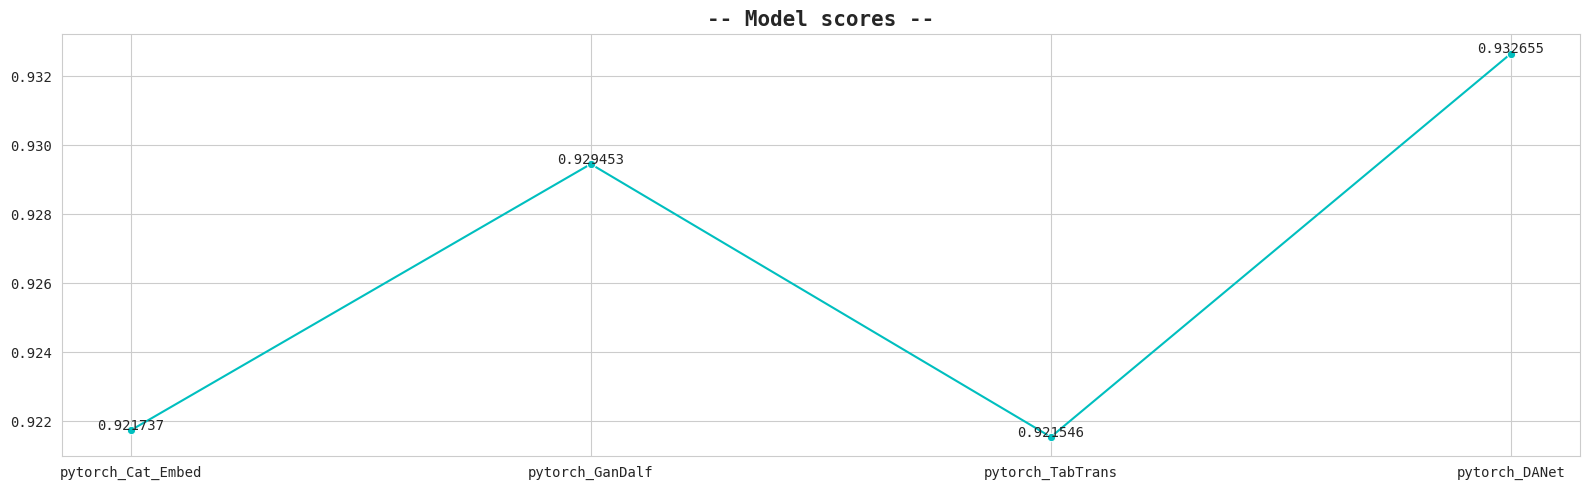

In [41]:
## -- Get model scores --
all_scores = {}

for k, v in all_predictions.items():
    for x, y in v.items():
        if x == 'score':
            all_scores[k] = y

plt.figure(figsize=(16, 5))
ax = sns.lineplot(all_scores, marker='o')

# ax.fill_between(range(len(all_model_scores)), all_model_scores.values(), alpha=0.3)
ax.set_title("-- Model scores --", fontsize=15, fontweight='semibold')
ax.tick_params('x', rotation=0)
# ax.set_ylim(0.94, 0.97)

add_ = 1e-5
for i, s in enumerate(all_scores.values()):
    ax.text(float(i), s+add_, s, ha='center', va='baseline')

plt.tight_layout()
plt.show()

pytorch_Cat_Embed_921737 saved!


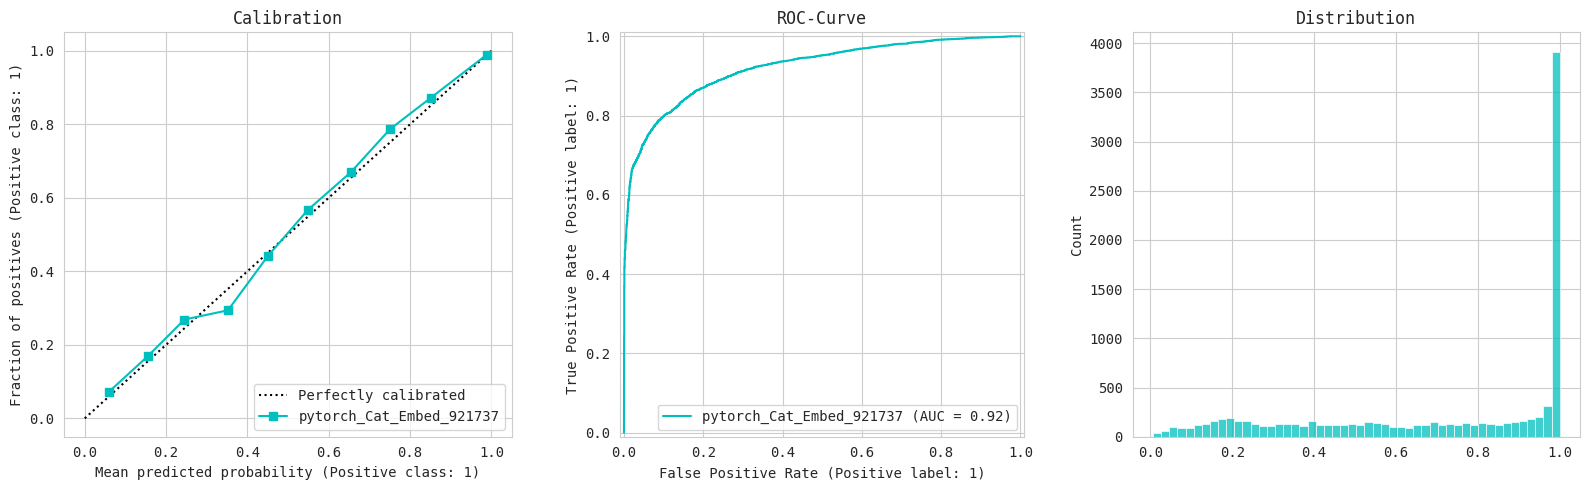


pytorch_GanDalf_929453 saved!


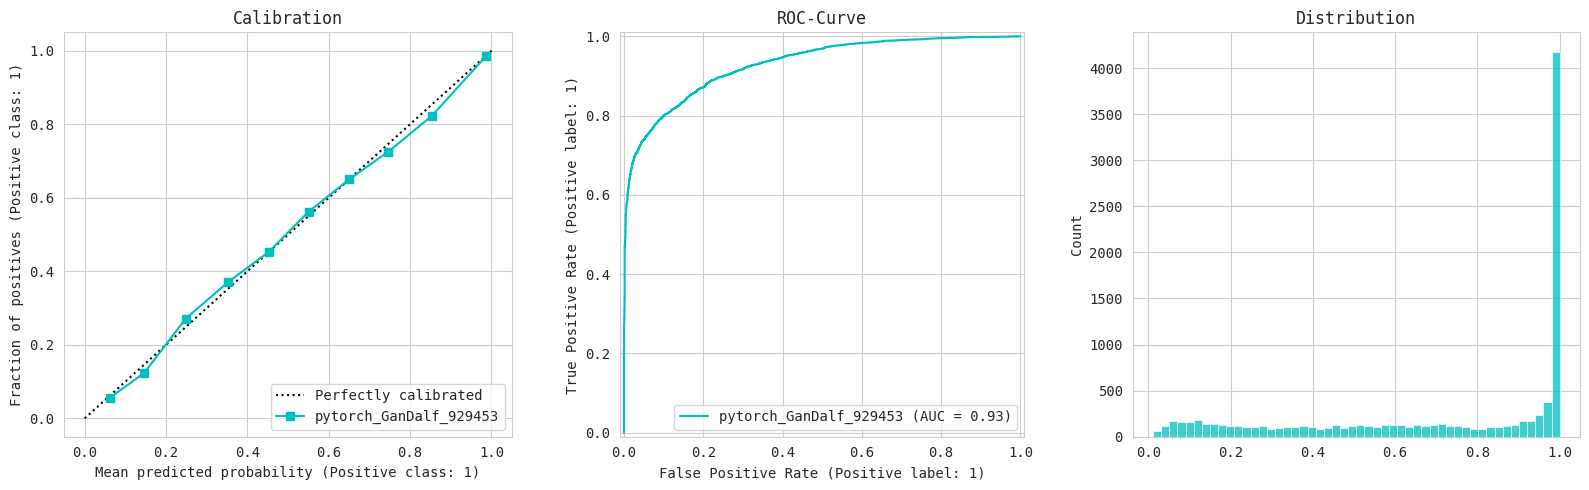


pytorch_TabTrans_921546 saved!


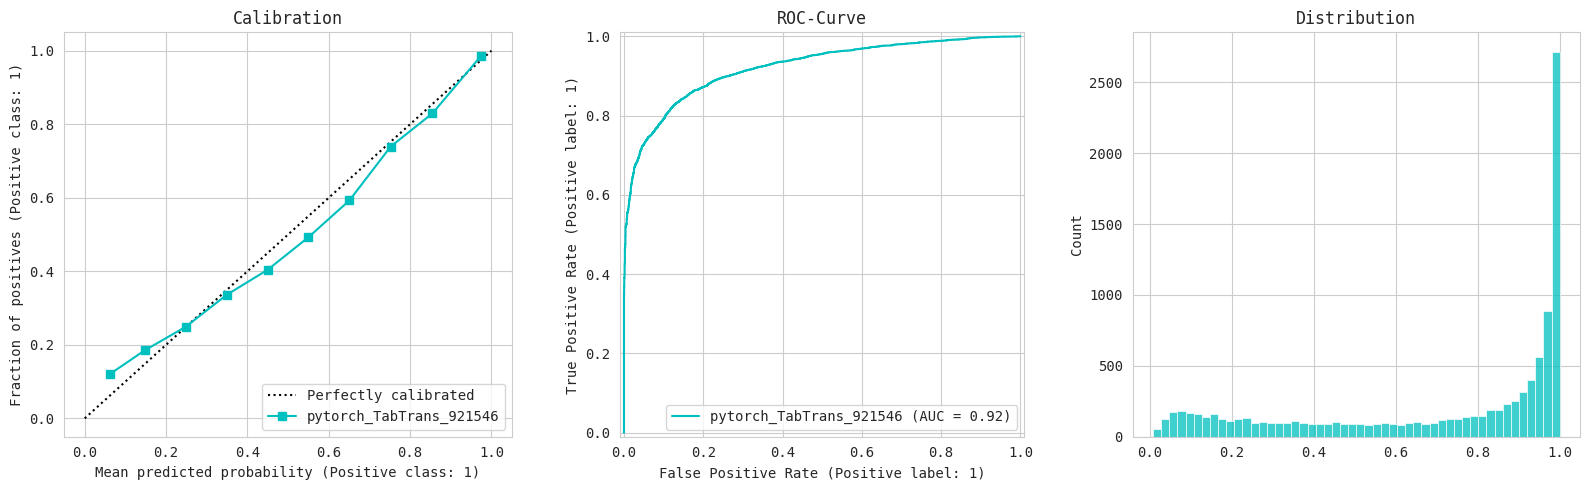


pytorch_DANet_932655 saved!


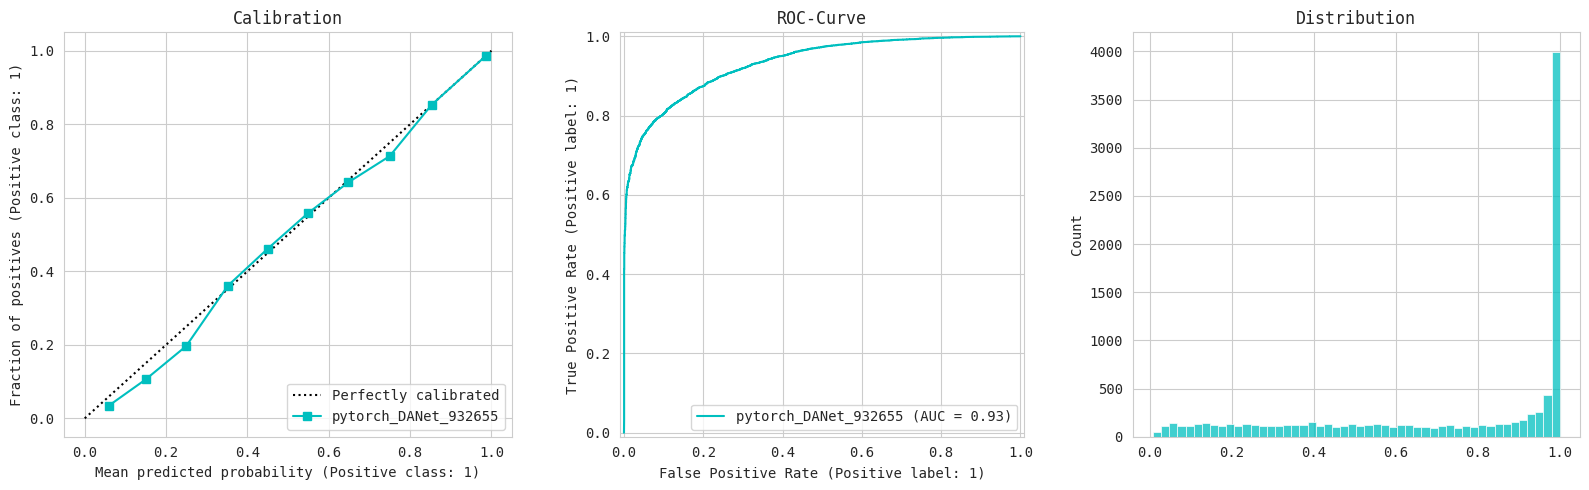

In [43]:
## -- Get oof predictions --
oof_predictions = []

for i, (k, v) in enumerate(all_predictions.items()):
    for key_, data_ in v.items():
        if key_ == "oof_preds":
            n = f"{k}_{str(all_scores[k]).split('.')[1]}"
            np.save(f"oof_{n}.npy", data_)
            print(f"{n} saved!")

            ## -- Plot distributions --
            _, axs = plt.subplots(1, 3, figsize=(16, 5)) 
            CalibrationDisplay.from_predictions(train_data[TARGET], data_, n_bins=10, name=n, ax=axs[0])
            axs[0].set_title("Calibration")

            RocCurveDisplay.from_predictions(train_data[TARGET], data_, name=n, ax=axs[1])
            axs[1].set_title("ROC-Curve")

            sns.histplot(data_, ax=axs[2], bins=50)
            axs[2].set_title("Distribution")
            
            plt.tight_layout()
            plt.show()

            print()

In [44]:
## -- Save test predictions/submissions --
model_results = {}

for i, (k, v) in enumerate(all_predictions.items()):
    for j, (x, y) in enumerate(v.items()):
        if x == "test_preds":
            ## -- Base submission file --
            n = f"{k}_{str(all_scores[k]).split('.')[1]}"
            np.save(f"test_{n}.npy", y)

            submit[TARGET] = y
            submit.to_csv(f"submit_{n}.csv", index=False)
            print(f"{n} saved! {y.shape}")

            model_results[n] = y

pytorch_Cat_Embed_921737 saved! (296302,)
pytorch_GanDalf_929453 saved! (296302,)
pytorch_TabTrans_921546 saved! (296302,)
pytorch_DANet_932655 saved! (296302,)


In [45]:
pd.DataFrame(model_results)

,pytorch_Cat_Embed_921737,pytorch_GanDalf_929453,pytorch_TabTrans_921546,pytorch_DANet_932655
0,0.984578,0.987256,0.962173,0.985435
1,0.819949,0.748161,0.886424,0.843901
2,0.978177,0.992134,0.977064,0.985405
3,0.917337,0.948580,0.930912,0.938653
4,0.990541,0.994791,0.989317,0.993587
...,...,...,...,...
296297,0.999997,0.997753,0.999660,0.999997
296298,0.769937,0.812699,0.811619,0.791590
296299,0.409654,0.442927,0.443685,0.396673
296300,0.287186,0.413254,0.241723,0.351390


In [50]:
## -- Inspect model --
all_data   = []
all_models = []
all_evaluations = []

for k, v in all_predictions.items():
    for x, y in v.items():
        if x == 'val_data':
            all_data.append(y)
        elif x == 'model':
            all_models.append(y)
        elif x == 'eval_results':
            all_evaluations.append(y)

for m in all_models:
    display(m)

Layer,Type,Params,In sizes,Out sizes
_backbone,CategoryEmbeddingBackbone,45760,?,?
_embedding_layer,Embedding1dLayer,56,?,?
head,LinearHead,130,?,?
loss,CrossEntropyLoss,0,?,?


Layer,Type,Params,In sizes,Out sizes
_backbone,GANDALFBackbone,10818,?,?
_embedding_layer,Embedding1dLayer,56,?,?
_head,Sequential,38,?,?
loss,CrossEntropyLoss,0,?,?


Layer,Type,Params,In sizes,Out sizes
_backbone,TabTransformerBackbone,271314,?,?
_embedding_layer,Embedding2dLayer,472,?,?
_head,LinearHead,212,?,?
loss,CrossEntropyLoss,0,?,?


Layer,Type,Params,In sizes,Out sizes
_backbone,DANetBackbone,442365,?,?
_embedding_layer,Embedding1dLayer,56,?,?
_head,LinearHead,130,?,?
loss,CrossEntropyLoss,0,?,?


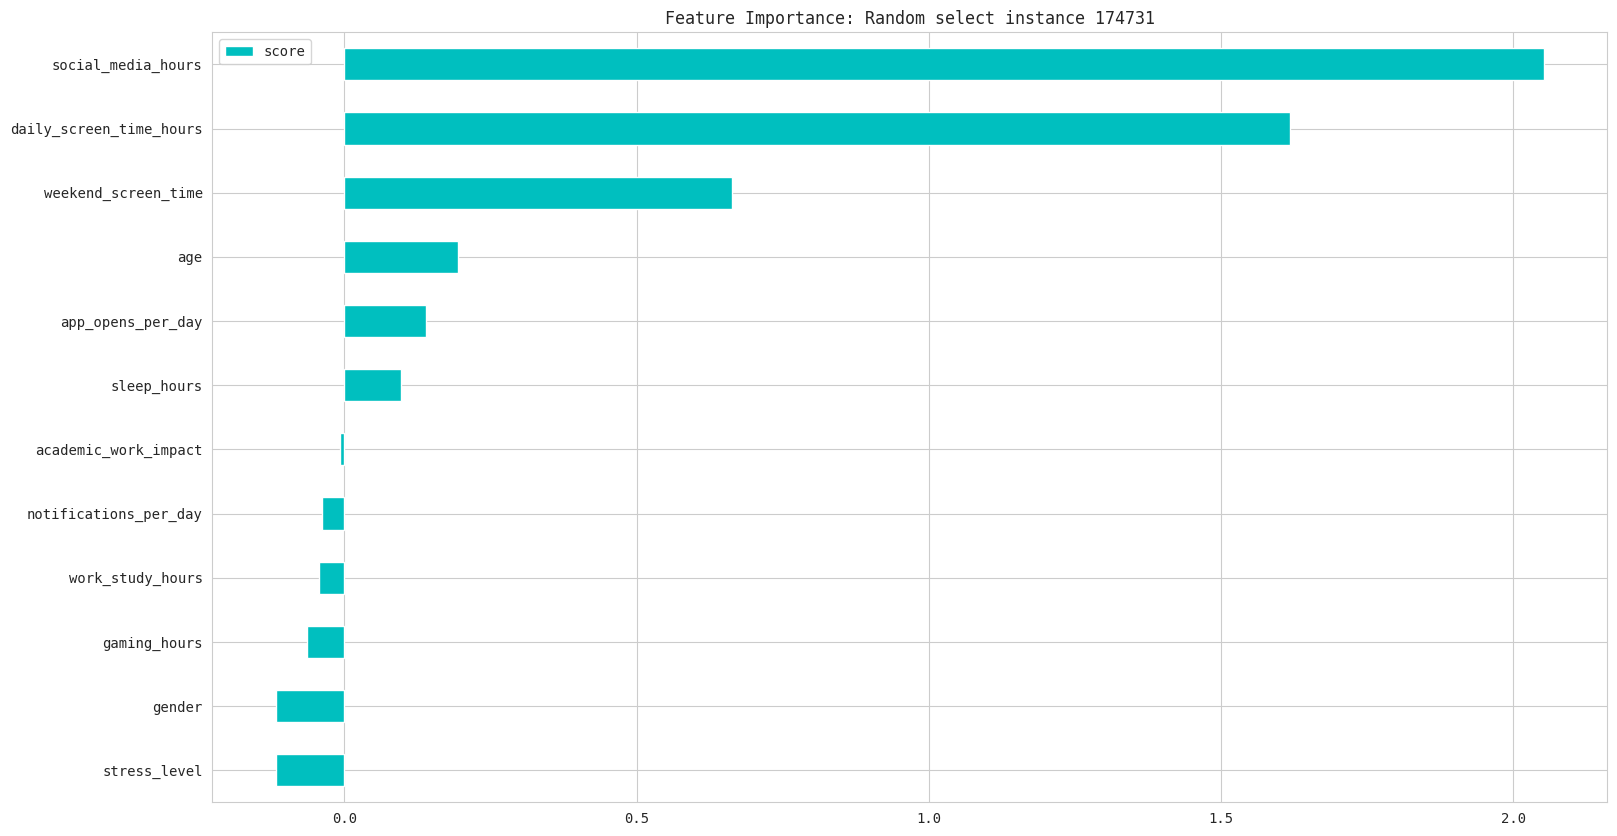

In [53]:
## -- Feature importances: Single instance --
INSTANCE = all_data[0].sample(1)

single_importance = all_models[0].explain(INSTANCE, method="GradientShap", baselines="b|10000")\
                                 .T.rename(columns={0: "score"}).sort_values("score")

single_importance.plot.barh(figsize=(18, 10))
# plt.yticks(range(len(single_importance.index)), [*single_importance.index], rotation=90)
plt.title(f"Feature Importance: Random select instance {INSTANCE.index[0]}")
plt.show()

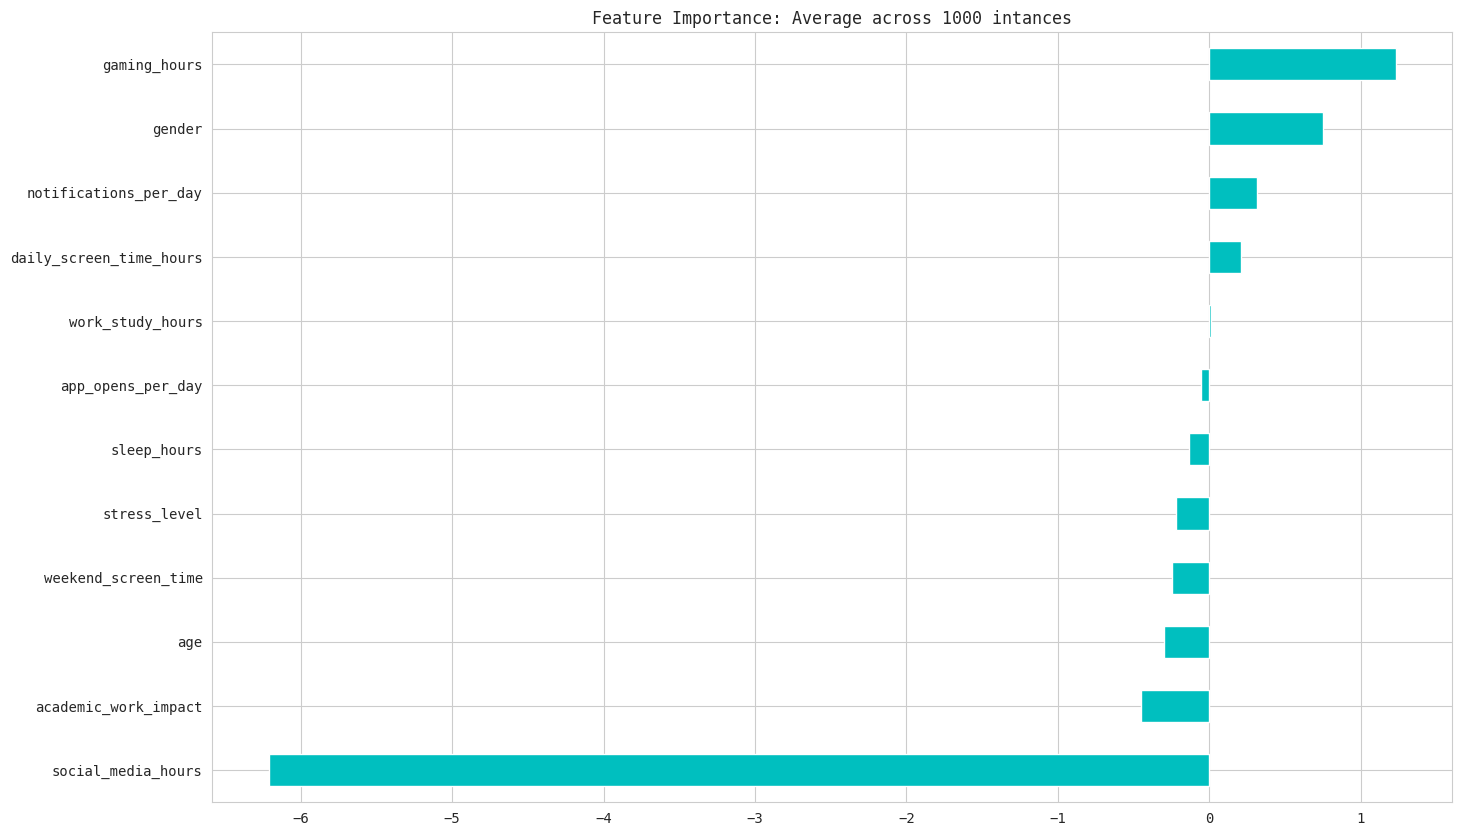

In [54]:
## -- Feature importances: Average across multiple instances --
SAMPLE_SIZE = all_data[0].sample(1000)

avg_importance = all_models[0].explain(SAMPLE_SIZE, method="IntegratedGradients", baselines=0)\
                              .T.mean(axis=1).sort_values()

avg_importance.plot.barh(figsize=(16, 10))
# plt.xticks(range(len(avg_importance.index)), [*avg_importance.index], rotation=90)
plt.title(f"Feature Importance: Average across {len(SAMPLE_SIZE)} intances")
plt.show()

In [55]:
# !rm -r /kaggle/working/

rm: cannot remove '/kaggle/working/': Device or resource busy
